# Домашнее задание 2. Вариант NLP: NER - детекция в тексте

**Дедлайн:** вс 22.11.2026, 23:59

В ДЗ2 вы выбираете **один** вариант: CV (детекция объектов на YOLO) или NLP (этот ноутбук). Номера задач и баллы в вариантах совпадают. NER (named entity recognition) - это детекция в тексте: найти спаны, т.е. непрерывные куски из слов, и для каждого предсказать тип сущности. Вы берете предобученный энкодер с Hugging Face Hub, находите свой датасет, приводите разметку к формату модели, дообучаете, считаете метрики и разбираете ошибки.

- Заполняйте места с `# ваш код` и ячейки «**Ответ:**». Сигнатуры функций и открытые тесты не меняйте, свои ячейки добавлять можно. Открытые тесты проверяют часть контракта, при проверке будут и другие входы
- В ответах опирайтесь на свои числа: наблюдение, объяснение, ограничение вывода. Обычно хватает 2-4 предложений. Отсутствие ожидаемого эффекта - нормальный результат, если эксперимент корректный и вы это обсудили
- Свой код обязателен в 1.2 (параметры по блокам), 2.2 (конвертация разметки + тесты), 3.1 (словарный бейзлайн), 5.1 (категоризация ошибок). Для обучения и стандартных метрик можно `transformers` (`Trainer` или свой цикл) и `seqeval`
- `FAST_MODE = True` - отладка на маленьком подмножестве, весь ноутбук не дольше 5 минут на T4. Финальный прогон - с `FAST_MODE = False`, ориентир до ~1 часа на T4. Бонусы включаются через `BONUS_TASKS`, выключенные бонусы пропускаются, даже если их ячейки пустые
- Запуск: Colab (T4) или Kaggle (GPU T4, ноутбук сам берет одну карту). Зависимости ставит первая ячейка, пины те же, что в `requirements_nlp.txt`. Укажите устройство в ячейке ниже, время обучения возвращает ваш `train_ner` (4.1)
- Только открытые модели и данные. Лицензию модели и датасета укажите в 1.1 и 2.1
- Можно документацию, материалы курса и код семинаров - укажите источник
- Сдача как в ДЗ1: PR в свой публичный GitHub-репозиторий, ссылка на него - в Google-форму (ссылку на форму дадим отдельно). В PR - ноутбук с outputs и `artifacts/metrics.json` (пишется в 5.3, перед бонусами). Датасет (`data/`), `runs/` и веса моделей не кладите, достаточно кода скачивания; файл доразметки из 6.1 - кладите
- Для полной сдачи: Restart & Run All с `FAST_MODE = False`, сохранить outputs. Если сдаете частичное решение, перечислите нерешенные задачи в ячейке ниже и приложите то, что получилось. Ошибки не скрывайте: баллы ставятся по задачам, одна ошибка не обнуляет остальные
- ДЗ индивидуальное

| раздел | задачи | баллы |
|---|---|---|
| 1. Модель | 1.1 модель и ревизия · 1.2 архитектура | 4 |
| 2. Данные | 2.1 датасет · 2.2 формат разметки | 4 |
| 3. Бейзлайн | 3.1 бейзлайн до дообучения | 2 |
| 4. Дообучение | 4.1 обучение · 4.2 метрики | 6 |
| 5. Анализ | 5.1 разбор ошибок · 5.2 абляция · 5.3 выводы | 4 |
| 6*. Бонусы | 6.1 доразметка · 6.2 другая модель · 6.3 сдвиг · 6.4 экспорт и скорость · 6.5 пороги | до +4 из 5.5 |
| итого | | 20 + 4 |

Соответствие с CV-вариантом - задачи те же, меняется «геометрия»: вместо прямоугольника на картинке - отрезок из слов в предложении.

| CV (детекция на картинке) | NLP (NER в тексте) |
|---|---|
| бокс | спан: (начало, конец, тип) в индексах слов |
| класс объекта | тип сущности (PER, ORG, LOC, ...) |
| фон | тег `O` |
| VOC / COCO -> YOLO-формат | слова и спаны -> BIO-теги под сабворды токенизатора |
| backbone -> neck -> head | эмбеддинги -> слои энкодера -> голова token classification |
| mAP по IoU | F1 по сущностям (`seqeval`, спан засчитывается при точном совпадении границ и типа) |
| ошибка локализации (IoU 0.1-0.5) | ошибка границы спана (тип верный, спаны пересекаются) |
| ошибка класса | ошибка типа |
| пропуск / лишний бокс | пропуск / лишний спан |
| порог conf | порог уверенности спана |

Внутренности трансформера (attention, устройство слоя энкодера) - тема ДЗ3. Здесь энкодер рассматривается на уровне блоков.

Примерный план: первая неделя - разделы 1-3 (модель, датасет, разметка, бейзлайн), вторая - обучение, метрики, разбор ошибок, абляция и финальный прогон.

**Сведения о сдаче.** Укажите устройство (Colab T4 / Kaggle / свое), выбранные модель и датасет (ссылка и лицензия), бонусы, внешние источники и нерешенные задачи (если есть).

**Ответ:**
- **Устройство и запуск** - CPU в Google Colab
- **Основная модель** - [cointegrated/rubert-tiny2](https://huggingface.co/cointegrated/rubert-tiny2), лицензия MIT
- **Датасет** - русская часть [Babelscape/wikineural](https://huggingface.co/datasets/Babelscape/wikineural), лицензия CC BY-NC-SA 4.0. Для финального прогона я взяла 8 000 предложений из train и по 1 000 из validation и test после перемешивания с SEED = 0. Статистика в разделе 2.1 посчитана по полным сплитам.
- **Выполненные бонусы** - 6.2, 6.3, 6.4, 6.5
- **Внешние источники** - [описание и сравнение моделей RuBERT](https://habr.com/ru/articles/669674/), [карточка RuBERT-base](https://huggingface.co/DeepPavlov/rubert-base-cased), [статья авторов WikiNEuRal](https://aclanthology.org/2021.findings-emnlp.215/), [документация Trainer](https://huggingface.co/docs/transformers/main/en/main_classes/trainer) и [документация PyTorch по квантизации](https://docs.pytorch.org/docs/stable/generated/torch.ao.quantization.quantize_dynamic.html).
- **Нерешённые задачи** - по обязательной части нет. Бонус 6.1 с ручной разметкой я пропустила.

In [2]:
# Зависимости (пины те же, что в requirements_nlp.txt). Запускайте эту ячейку первой, тогда перезапуск сессии не нужен
# Безвредный шум: строки ERROR от pip про bigframes / cudf / pyarrow на Kaggle и предупреждение про HF_TOKEN ниже (токен не нужен)
# Локально: сначала torch под свою платформу (https://pytorch.org/get-started/locally/)
%pip install -q "torch>=2.4" "transformers==5.22.1" "datasets==5.1.0" "accelerate==1.15.0" "seqeval==1.2.2" numpy matplotlib

In [3]:
import os
os.environ.setdefault('CUDA_VISIBLE_DEVICES', '0')   # одна GPU: на Kaggle T4 x2 иначе Trainer включит DataParallel (медленнее и хуже)
import collections
import copy
import json
import math
import random
import re
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch

import datasets
import transformers
from datasets import DatasetDict, load_dataset
from huggingface_hub import HfApi
from seqeval.metrics import classification_report, f1_score, precision_score, recall_score
from transformers import (AutoModelForTokenClassification, AutoTokenizer, DataCollatorForTokenClassification,
                          Trainer, TrainingArguments)

transformers.logging.set_verbosity_error()
plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 11

print(f'torch {torch.__version__}, transformers {transformers.__version__}, datasets {datasets.__version__}')
print(f'CUDA available: {torch.cuda.is_available()}')

torch 2.14.1+cpu, transformers 5.22.1, datasets 5.1.0
CUDA available: False


In [4]:
def get_device():
    if torch.cuda.is_available():
        return torch.device('cuda')
    if torch.backends.mps.is_available():
        return torch.device('mps')
    return torch.device('cpu')


def set_seed(seed=0):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    transformers.set_seed(seed)


device = get_device()
DEVICE_NAME = torch.cuda.get_device_name(0) if device.type == 'cuda' else device.type
set_seed(0)
print(device, DEVICE_NAME)

cpu cpu


In [5]:
FAST_MODE = False   # True - отладка, False - финальный прогон
BONUS_TASKS = {'6.2', '6.3', '6.4', '6.5'}   # например {'6.3', '6.5'}; пустое множество отключает все бонусы
assert BONUS_TASKS <= {'6.1', '6.2', '6.3', '6.4', '6.5'}

SEED = 0
N_TRAIN = 2000 if FAST_MODE else 8_000
N_EVAL = 500 if FAST_MODE else 1_000
EPOCHS = 1 if FAST_MODE else 3
MAX_LENGTH = 128                        # длина в сабвордах, длиннее - обрезается
ARTIFACTS = Path('artifacts')
ARTIFACTS.mkdir(exist_ok=True)
RUN_TIMES = {}

---
# 1. Модель

## 1.1 Модель и ревизия (1.5 балла)

Выберите предобученный энкодер на Hugging Face Hub, подходящий под язык и домен вашего датасета. Модель на Hub - это git-репозиторий: владелец может перезалить веса, токенизатор или конфиг, и `main` начнет указывать на другую версию. Поэтому зафиксируйте `revision` - полный commit hash (40 символов). Его видно во вкладке «Files and versions» -> «History» или через `HfApi().model_info(MODEL_ID).sha`.

Ориентиры для выбора (не исчерпывающий список):
- русский: `cointegrated/rubert-tiny2` (29M параметров, быстрый), `DeepPavlov/rubert-base-cased` (~180M)
- многоязычные: `FacebookAI/xlm-roberta-base` (~280M), `google-bert/bert-base-multilingual-cased` (~180M), `distilbert/distilbert-base-multilingual-cased`
- английский: `google-bert/bert-base-cased`, `FacebookAI/roberta-base` (в 1.1 задайте `TOKENIZER_KWARGS = {'add_prefix_space': True}`), `microsoft/deberta-v3-small`
- биомедицина: `dmis-lab/biobert-base-cased-v1.2`

Нужен fast-токенизатор: `word_ids()`, без которого не выровнять метки по сабвордам, есть только у него. На T4 модель до ~300M параметров дообучается на датасете в десятки тысяч предложений за минуты - десятки минут.

Нужен базовый энкодер, а не модель, уже дообученная на NER: с ней 3.1 и 4.1 теряют смысл.

In [6]:
print(HfApi().model_info("cointegrated/rubert-tiny2").sha)

e8ed3b0c8bbf4fb6984c3de043bf7d2f4e5969ae


In [7]:
MODEL_ID = "cointegrated/rubert-tiny2"   # ваш код: id модели на Hugging Face Hub
REVISION = 'e8ed3b0c8bbf4fb6984c3de043bf7d2f4e5969ae'   # ваш код: полный commit hash (40 символов)
TOKENIZER_KWARGS = {}   # для roberta-base: {'add_prefix_space': True}

In [8]:
assert MODEL_ID, 'укажите MODEL_ID'
assert re.fullmatch(r'[0-9a-f]{40}', REVISION or ''), 'REVISION - полный commit hash из 40 символов, а не main и не тег'
info = HfApi().model_info(MODEL_ID, revision=REVISION, files_metadata=True)
card = info.card_data.to_dict() if info.card_data else {}
weights = {s.rfilename: f'{s.size / 2**20:.0f} MB' for s in info.siblings if s.rfilename.endswith(('.safetensors', '.bin'))}
print(f'model:    {MODEL_ID}\nrevision: {info.sha}\nlicense:  {card.get("license")}\nlanguage: {card.get("language")}')
print(f'updated:  {info.last_modified}\nweights:  {weights}')

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, revision=REVISION, **TOKENIZER_KWARGS)
assert tokenizer.is_fast, 'нужен fast-токенизатор: word_ids() есть только у него'
print(type(tokenizer).__name__, 'vocab size', tokenizer.vocab_size)
print(tokenizer.tokenize('Петр Ильич Чайковский родился в Воткинске'))

model:    cointegrated/rubert-tiny2
revision: e8ed3b0c8bbf4fb6984c3de043bf7d2f4e5969ae
license:  mit
language: ['ru']
updated:  2025-12-30 08:33:24+00:00
weights:  {'model.safetensors': '112 MB', 'pytorch_model.bin': '112 MB'}
BertTokenizer vocab size 83828
['Петр', 'Ильич', 'Чайк', '##овский', 'родился', 'в', 'Вот', '##кинс', '##ке']


**Вопрос.** Почему вы выбрали эту модель: язык и данные предобучения, размер и скорость, ожидаемое качество на NER, лицензия? Сравните с 1-2 альтернативами из списка выше: размер, язык, скорость, качество по карточке. Что может сломаться в вашем ноутбуке через полгода, если не фиксировать `revision`?

**Ответ:**
Я выбрала cointegrated/rubert-tiny2, потому что в задании буду работать с русскими текстами из WikiNEuRal. Модель уже обучалась понимать контекст, например угадывать скрытые слова. У неё 29,4 млн параметров и лицензия MIT.

rubert-base-cased обучалась на русской Википедии и новостях. У неё около 180 млн параметров, поэтому я ожидаю, что дообучение rubert-tiny2 на T4 займёт меньше времени. В тестах автора rubert-tiny2 набрала более высокий F1 по токенам, чем первая rubert-tiny, на двух задачах NER. На WikiNEuRal я проверю качество после дообучения.

Я зафиксировала revision, чтобы при каждом запуске загружались те же веса, конфигурация и токенизатор. Если обновить файлы модели, без фиксации версии токенизация и результаты могут поменяться.

## 1.2 Архитектура (2.5 балла)

Энкодер для token classification на уровне блоков:

1. **эмбеддинги** - сабворд -> вектор размера hidden (таблица `vocab_size x hidden`) + позиционные эмбеддинги (у DeBERTa их нет, позиции учитываются в attention) и type-эмбеддинги (у BERT-подобных), LayerNorm, dropout. Выход `(B, T, H)`
2. **N слоев энкодера** - одинаковые по форме блоки `(B, T, H) -> (B, T, H)`, в которых токены обмениваются информацией друг с другом. Устройство слоя (attention, FFN) - ДЗ3
3. **голова token classification** - dropout + `Linear(H, K)` к каждому токену независимо, K - число BIO-тегов. Выход - logits `(B, T, K)`
4. **сборка спанов** - argmax по тегам на первом сабворде каждого слова, затем BIO -> спаны (это уже не нейросеть, а ваш код из 2.2)

Ниже модель создается с головой на `N_DEMO_LABELS = 7` тегов (O + B/I для трех типов), под ваш датасет голову пересоздает `make_model` (3.1, 4.1).

1. Реализуйте `params_by_block(model)` - число параметров по блокам: `embeddings`, `encoder` (все слои), `head` (классификатор), `other` (все остальное: у BERT и RoBERTa для token classification здесь 0, у DeBERTa - `encoder.rel_embeddings` и общий `encoder.LayerNorm`) и `layers` - список по слоям энкодера. Сумма блоков должна совпасть с общим числом параметров
2. Прогоните dummy-вход `demo_texts` (батч из двух предложений, уже разбитых на слова) через токенизатор и модель с `output_hidden_states=True`, сохраните результат токенизатора в `enc`, выход модели в `out` и выведите формы: `input_ids`, `attention_mask`, все `hidden_states`, `logits`

In [9]:
N_DEMO_LABELS = 7
demo_model = AutoModelForTokenClassification.from_pretrained(MODEL_ID, revision=REVISION, num_labels=N_DEMO_LABELS)
cfg = demo_model.config
print({k: getattr(cfg, k, None) for k in ['model_type', 'vocab_size', 'hidden_size', 'num_hidden_layers',
                                          'num_attention_heads', 'intermediate_size', 'max_position_embeddings']})
for name, module in demo_model.named_children():
    print(f'{name:<12} {type(module).__name__}')

Loading weights:   0%|          | 0/53 [00:00<?, ?it/s]

{'model_type': 'bert', 'vocab_size': 83828, 'hidden_size': 312, 'num_hidden_layers': 3, 'num_attention_heads': 12, 'intermediate_size': 600, 'max_position_embeddings': 2048}
bert         BertModel
dropout      Dropout
classifier   Linear


In [10]:
def params_by_block(model):
    # -> {'embeddings': int, 'encoder': int, 'head': int, 'other': int, 'layers': [int, ...]}
    backbone = model.base_model

    embeddings = sum(p.numel() for p in backbone.embeddings.parameters())
    layers = [
        sum(p.numel() for p in layer.parameters())
        for layer in backbone.encoder.layer
    ]
    encoder = sum(layers)
    head = sum(p.numel() for p in model.classifier.parameters())
    total = sum(p.numel() for p in model.parameters())

    return {
        "embeddings": embeddings,
        "encoder": encoder,
        "head": head,
        "other": total - embeddings - encoder - head,
        "layers": layers,
    }


In [11]:
blocks = params_by_block(demo_model)
total = sum(p.numel() for p in demo_model.parameters())
assert sum(blocks[k] for k in ['embeddings', 'encoder', 'head', 'other']) == total
assert blocks['head'] == cfg.hidden_size * N_DEMO_LABELS + N_DEMO_LABELS
assert len(blocks['layers']) == cfg.num_hidden_layers and sum(blocks['layers']) == blocks['encoder'], \
    'encoder - сумма слоев, все вне слоев (например, rel_embeddings у DeBERTa) - в other'
assert blocks['embeddings'] >= cfg.vocab_size * cfg.hidden_size
for k in ['embeddings', 'encoder', 'head', 'other']:
    print(f'{k:<11}{blocks[k]:>13,}  {blocks[k] / total:6.1%}')
print(f'{"total":<11}{total:>13,}\nper layer: {blocks["layers"]}')

embeddings    26,794,560   92.1%
encoder        2,301,552    7.9%
head               2,191    0.0%
other                  0    0.0%
total         29,098,303
per layer: [767184, 767184, 767184]


In [12]:
demo_texts = [['Петр', 'Чайковский', 'родился', 'в', 'Воткинске', '.'],
              ['ITMO', 'University', 'is', 'in', 'Saint', 'Petersburg']]
enc = tokenizer(
    demo_texts,
    is_split_into_words=True,
    padding=True,
    return_tensors="pt",
).to(device)

demo_model.to(device).eval()
with torch.inference_mode():
    out = demo_model(**enc, output_hidden_states=True)

print("input_ids", tuple(enc["input_ids"].shape))
print("attention_mask", tuple(enc["attention_mask"].shape))
for i, state in enumerate(out.hidden_states):
    print(f"hidden_states[{i}]", tuple(state.shape))
print("logits", tuple(out.logits.shape))

input_ids (2, 11)
attention_mask (2, 11)
hidden_states[0] (2, 11, 312)
hidden_states[1] (2, 11, 312)
hidden_states[2] (2, 11, 312)
hidden_states[3] (2, 11, 312)
logits (2, 11, 7)


In [13]:
B, T = enc['input_ids'].shape
assert B == 2 and out.logits.shape == (B, T, N_DEMO_LABELS)
assert len(out.hidden_states) == cfg.num_hidden_layers + 1
assert all(h.shape == (B, T, cfg.hidden_size) for h in out.hidden_states)

# скорость прямого прохода: батч 32 предложения x 62 слова (сколько это сабвордов - см. вывод)
x = {k: v.to(device) for k, v in tokenizer([['слово'] * 62] * 32, is_split_into_words=True, return_tensors='pt').items()}
demo_model.to(device).eval()
with torch.inference_mode():
    demo_model(**x)
    if device.type == 'cuda':
        torch.cuda.synchronize()
    start = time.perf_counter()
    for _ in range(5):
        demo_model(**x)
    if device.type == 'cuda':
        torch.cuda.synchronize()
print(f'forward 32 x {x["input_ids"].shape[1]}: {(time.perf_counter() - start) / 5 * 1000:.1f} ms на {DEVICE_NAME}')
demo_model = demo_model.cpu()

forward 32 x 64: 985.4 ms на cpu


**Вопрос.** Опишите путь входа по блокам с формами тензоров из вашего вывода. Какой блок содержит больше всего параметров и почему? В каком блоке токены обмениваются информацией, а где каждый токен обрабатывается независимо? Почему `T` в logits больше числа слов?

**Ответ:**
У меня в батче два предложения. После токенизации input_ids и attention_mask имеют форму (2, 11). Эмбеддинги превращают каждый токен в вектор из 312 чисел, поэтому форма становится (2, 11, 312). Все три слоя энкодера сохраняют эту форму, но меняют сами векторы с учётом контекста. Всего получилось четыре hidden_states: выход эмбеддингов и выход каждого из трёх слоёв. Голова выдаёт семь оценок на позицию, поэтому форма logits — (2, 11, 7).

Больше всего параметров в эмбеддингах — около 26,8 млн, или 92% всей модели. Только в таблице токенов для каждого из 83 828 токенов хранится вектор из 312 чисел. Токены обмениваются информацией в слоях энкодера через self-attention, а голова обрабатывает каждую позицию отдельно. T больше числа слов, потому что некоторые слова делятся на части, добавляются [CLS] и [SEP], а короткое предложение при необходимости дополняется [PAD]

---
# 2. Данные

## 2.1 Датасет (1.5 балла)

Найдите датасет для NER на Hugging Face Hub или в другом открытом источнике, подходящий под вашу модель по языку. Опишите источник, лицензию, как размечали, типы сущностей, размер и сплиты; посчитайте статистику: число сущностей каждого типа по сплитам, распределение длин спанов (в словах), длины предложений.

**Нельзя брать WikiANN ru** (`unimelb-nlp/wikiann`, конфиг `ru`) - на нем ниже показан пример формата. Другие языки WikiANN брать можно.

Подсказки - датасеты, которые на момент выдачи загружаются текущей библиотекой `datasets` (проверено 31.10.2026, `datasets` 5.1). Библиотека больше не исполняет loading-скрипты, поэтому часть датасетов грузится из служебной ветки с parquet-версией - так, как написано в списке:

Русский:
- `Babelscape/wikineural` - WikiNEuRal, PER / ORG / LOC / MISC, 9 языков; для русского сплиты `train_ru`, `val_ru`, `test_ru`; CC BY-NC-SA 4.0
- `Babelscape/multinerd` - MultiNERD, 15 типов, 10 языков, колонка `lang` - отфильтруйте `ru`; CC BY-NC-SA 4.0
- `load_dataset('RCC-MSU/collection3', revision='refs/convert/parquet')` - Collection3, новости, PER / ORG / LOC, уже `tokens` + `ner_tags`
- `undefinedhorizons/nerus_lenta` - Nerus: новости Lenta.ru с автоматической разметкой PER / LOC / ORG, только `train` и очень большой - возьмите подмножество и сами отделите validation и test
- `gusevski/factrueval2016` - FactRuEval-2016, новости; вся разметка в одной вложенной колонке `data` - разобрать в предложения, слова и BIO
- `load_dataset('iluvvatar/RuNNE', revision='refs/convert/parquet')` и то же для `iluvvatar/NEREL` - новости, 29 типов, вложенные сущности, спаны по символам в тексте. Нужны разбиение на предложения и слова (целый текст длиннее `MAX_LENGTH = 128` сабвордов, хвост обрежется), BIO и правило для вложенных (например, оставить только внешние) - самая содержательная конвертация из списка

Другие языки:
- `unimelb-nlp/wikiann` - WikiANN, 176 языков (любой, кроме `ru`), PER / ORG / LOC
- `lhoestq/conll2003`, `tomaarsen/conll2003` или `load_dataset('eriktks/conll2003', revision='refs/convert/parquet')` - CoNLL-2003, английский, PER / ORG / LOC / MISC
- `DFKI-SLT/few-nerd`, конфиг `supervised` - Few-NERD, английский, 8 крупных и 66 мелких типов; теги в IO-схеме (без `B-` и `I-`) - переведите в BIO; CC BY-SA 4.0
- `load_dataset('tner/wnut2017', revision='refs/convert/parquet')` - WNUT-17, соцсети, редкие и новые сущности; имена тегов - в файле `dataset/label.json` репозитория

Биомедицина (английский):
- `load_dataset('ncbi/ncbi_disease', revision='refs/convert/parquet')` - NCBI-disease, один тип Disease
- `load_dataset('tner/bc5cdr', revision='refs/convert/parquet')` - BC5CDR, Chemical / Disease, теги в колонке `tags`: `{"O": 0, "B-Chemical": 1, "B-Disease": 2, "I-Disease": 3, "I-Chemical": 4}`

Если `load_dataset('<id>')` падает из-за loading-скрипта, берите ветку `revision='refs/convert/parquet'` (как в списке) или сырые файлы: `load_dataset('json', data_files='hf://datasets/<id>/<путь к файлу>')`. Датасеты из списка разрешены, лицензию укажите, как в карточке.

Если сплита validation или test нет, отделите их сами (`train_test_split` с фиксированным seed). Если датасет очень большой, возьмите подмножество и укажите это.

Контракт для остального ноутбука (после 2.2): `raw` - `DatasetDict` со сплитами `train`, `validation`, `test`, у каждого примера `tokens` (список слов) и `ner_tags` (список id тегов той же длины); `LABEL_NAMES` - список BIO-тегов, `LABEL_NAMES[i]` - тег с id `i`, тег `O` обязателен.

Если у `ner_tags` нет имен тегов (в `features` список чисел, а не `ClassLabel`; так у WikiNEuRal, MultiNERD и `lhoestq/conll2003`), составьте `LABEL_NAMES` вручную по карточке датасета. Например, у WikiNEuRal: `['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC', 'B-MISC', 'I-MISC']`.

In [14]:
# пример формата на WikiANN ru (этот датасет брать нельзя)
example = load_dataset('unimelb-nlp/wikiann', 'ru', split='validation[:3]')
print(example)
print(example.features['ner_tags'].feature.names)
for ex in example:
    print(list(zip(ex['tokens'], ex['ner_tags'])), ex['spans'])

Dataset({
    features: ['tokens', 'ner_tags', 'langs', 'spans'],
    num_rows: 3
})
['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC']
[('Отличился', 0), ('во', 0), ('время', 0), ('боёв', 0), ('в', 0), ('Германии', 5), ('.', 0)] ['LOC: Германии']
[('1920—1922', 0), ('—', 0), ('техник', 0), ('военно-гидротехнического', 0), ('отряда', 0), ('(', 0), ('Чернигов', 5), (')', 0), (',', 0)] ['LOC: Чернигов']
[('Нагибин', 1), (',', 2), ('Владимир', 2), ('Владимирович', 2)] ['PER: Нагибин , Владимир Владимирович']


In [15]:
DATASET_ID = "Babelscape/wikineural"
DATASET_CONFIG = None

base_url = f"https://huggingface.co/datasets/{DATASET_ID}/resolve/main"
raw = load_dataset(
    "json",
    data_files={
        "train": f"{base_url}/train_ru.jsonl",
        "validation": f"{base_url}/val_ru.jsonl",
        "test": f"{base_url}/test_ru.jsonl",
    },
)

LABEL_NAMES = [
    "O",
    "B-PER", "I-PER",
    "B-ORG", "I-ORG",
    "B-LOC", "I-LOC",
    "B-MISC", "I-MISC",
]

print(raw)
example = raw["train"][0]
print(list(zip(example["tokens"], [LABEL_NAMES[i] for i in example["ner_tags"]])))

DatasetDict({
    train: Dataset({
        features: ['tokens', 'ner_tags', 'lang'],
        num_rows: 92320
    })
    validation: Dataset({
        features: ['tokens', 'ner_tags', 'lang'],
        num_rows: 11540
    })
    test: Dataset({
        features: ['tokens', 'ner_tags', 'lang'],
        num_rows: 11580
    })
})
[('Детство', 'O'), ('провёл', 'O'), ('в', 'O'), ('Надьсомбате', 'B-LOC'), (',', 'O'), ('с', 'O'), ('1860', 'O'), ('г', 'O'), ('.', 'O')]


Сплит         Предложения       PER       ORG       LOC      MISC
train               92320     33282     20236     71090     23594
validation          11540      4007      2710      8851      2642
test                11580      3489      3051      8596      2962


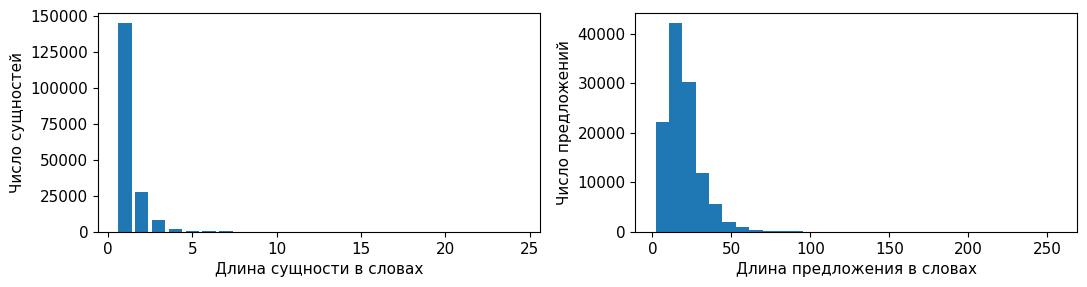

In [16]:
from seqeval.metrics.sequence_labeling import get_entities

entity_types = ["PER", "ORG", "LOC", "MISC"]
span_lengths = collections.Counter()
sentence_lengths = []

print(f'{"Сплит":<12} {"Предложения":>12} ' + " ".join(f"{t:>9}" for t in entity_types))

for split, examples in raw.items():
    counts = collections.Counter()
    for example in examples:
        words = example["tokens"]
        tags = [LABEL_NAMES[i] for i in example["ner_tags"]]
        assert len(words) == len(tags)
        sentence_lengths.append(len(words))

        for kind, start, end in get_entities(tags):
            counts[kind] += 1
            span_lengths[end - start + 1] += 1

    print(f"{split:<12} {len(examples):>12} " + " ".join(f"{counts[t]:>9}" for t in entity_types))

fig, axes = plt.subplots(1, 2, figsize=(11, 3))
lengths = sorted(span_lengths)
axes[0].bar(lengths, [span_lengths[length] for length in lengths])
axes[0].set(xlabel="Длина сущности в словах", ylabel="Число сущностей")
axes[1].hist(sentence_lengths, bins=30)
axes[1].set(xlabel="Длина предложения в словах", ylabel="Число предложений")
plt.tight_layout()
plt.show()

**Вопрос.** Откуда датасет, под какой лицензией и как его размечали (вручную, автоматически, полуавтоматически)? Какие типы сущностей, сколько их по сплитам, какие типы редкие? Какие особенности данных (длина спанов, длина предложений, шум разметки) могут повлиять на обучение?

**Ответ:**
Я взяла русскую часть WikiNEuRal (Babelscape/wikineural). Предложения взяты из Википедии, а разметку авторы сделали автоматически, используя базу знаний BabelNet и нейросетевые модели. Лицензия датасета - CC BY-NC-SA 4.0.

В разметке четыре типа сущностей: люди (PER), организации (ORG), места (LOC) и прочие (MISC). В train 92 320 предложений и 33 282 PER, 20 236 ORG, 71 090 LOC и 23 594 MISC. В validation 11 540 предложений и 4 007 PER, 2 710 ORG, 8 851 LOC и 2 642 MISC. В test 11 580 предложений и 3 489 PER, 3 051 ORG, 8 596 LOC и 2 962 MISC.

Места встречаются чаще всего во всех трёх сплитах. В train их примерно в 3,5 раза больше, чем организаций, поэтому у модели будет гораздо меньше примеров ORG. В validation и test самый редкий тип - MISC.

По графикам видно, что большинство сущностей состоят из одного слова, поэтому у модели меньше примеров, на которых она может научиться определять границы длинных названий. Много предложений имеют длину около 10-30 слов, но есть и длинные. Если предложение после токенизации превышает лимит в 128 токенов, его конец обрезается, и модель может потерять часть сущности. Ещё возможны ошибки автоматической разметки: например, если имя пропущено и размечено как O, при обучении модель получает подсказку, что это слово вне сущности.

## 2.2 Формат разметки (2.5 балла)

Модель предсказывает тег для каждого **сабворда**, а разметка дана по **словам** (или спанами по символам). Нужны две конвертации и тесты к ним.

1. `bio_to_spans(tags)` - BIO-теги слов -> список спанов `(start, end, type)`, `end` не включается. `B-X` начинает спан, `I-X` продолжает спан того же типа, иначе начинает новый (так делает `seqeval` в режиме по умолчанию), `O` закрывает спан. Тип может содержать дефис (`B-art-film` -> `art-film`)
2. `spans_to_bio(spans, n_words)` - обратно: спаны -> BIO-теги длины `n_words`
3. `align_labels(word_labels, word_ids, b_to_i=None)` - метки слов -> метки сабвордов. `word_ids` - выход `tokenizer(...).word_ids(i)`: номер слова для каждого сабворда, `None` у спецтокенов. По умолчанию метка слова ставится на его первый сабворд, спецтокены и продолжения слова получают `-100` (cross-entropy их игнорирует). Если передан словарь `b_to_i` (id тега `B-X` -> id тега `I-X`), метку получают все сабворды слова, у продолжений `B-X` заменяется на `I-X` - это вариант для абляции 5.2

Если ваш датасет не в формате «слова + BIO» (спаны по символам, IO-теги, CoNLL-текст), сначала приведите его к контракту из 2.1 и проверьте конвертацию на примерах глазами. Если датасет уже в BIO, сделайте обратную конвертацию: BIO -> спаны в JSON (`data/<split>_spans.jsonl`), прочитайте файл обратно, сконвертируйте в BIO и проверьте, что получилось то же самое (если в исходнике есть `I-X` без `B-X`, дословно не совпадет: сравните спаны и посчитайте такие предложения).

In [17]:
def bio_to_spans(tags):
    # ['B-PER', 'I-PER', 'O', 'B-LOC'] -> [(0, 2, 'PER'), (3, 4, 'LOC')]
    spans = []
    start, entity_type = None, None

    for index, tag in enumerate([*tags, "O"]):
        prefix, _, kind = tag.partition("-")

        if prefix == "I" and start is not None and kind == entity_type:
            continue

        if start is not None:
            spans.append((start, index, entity_type))
            start, entity_type = None, None

        if prefix in ("B", "I"):
            start, entity_type = index, kind

    return spans



def spans_to_bio(spans, n_words):
    # [(0, 2, 'PER')], 3 -> ['B-PER', 'I-PER', 'O']
    tags = ["O"] * n_words
    for start, end, kind in spans:
        tags[start] = f"B-{kind}"
        for index in range(start + 1, end):
            tags[index] = f"I-{kind}"
    return tags


def align_labels(word_labels, word_ids, b_to_i=None):
    # word_labels: id тегов слов; word_ids: номер слова для каждого сабворда (None - спецтокен) -> метки сабвордов
    labels = []
    seen = set()

    for word_id in word_ids:
        if word_id is None:
            labels.append(-100)
            continue

        tag = word_labels[word_id]
        if word_id in seen:
            tag = -100 if b_to_i is None else b_to_i.get(tag, tag)

        labels.append(tag)
        seen.add(word_id)

    return labels

In [18]:
tags = ['B-PER', 'I-PER', 'O', 'B-LOC', 'B-LOC', 'I-LOC', 'O', 'B-ORG']
assert bio_to_spans(tags) == [(0, 2, 'PER'), (3, 4, 'LOC'), (4, 6, 'LOC'), (7, 8, 'ORG')]
assert spans_to_bio(bio_to_spans(tags), len(tags)) == tags
assert bio_to_spans(['O', 'I-PER', 'I-PER', 'O']) == [(1, 3, 'PER')]       # I- без B- начинает спан
assert bio_to_spans(['B-PER', 'I-LOC', 'I-LOC']) == [(0, 1, 'PER'), (1, 3, 'LOC')]
assert bio_to_spans(['B-art-film', 'I-art-film', 'O']) == [(0, 2, 'art-film')]
assert bio_to_spans([]) == [] and bio_to_spans(['O'] * 3) == [] and spans_to_bio([], 2) == ['O', 'O']

rng = random.Random(0)
for _ in range(2000):   # туда-обратно на случайных спанах
    n, pos, spans = rng.randint(0, 15), 0, []
    while True:
        start = pos + rng.randint(0, 3)
        end = start + rng.randint(1, 4)
        if end > n:
            break
        spans.append((start, end, rng.choice(['PER', 'LOC', 'ORG'])))
        pos = end
    assert bio_to_spans(spans_to_bio(spans, n)) == spans, spans

word_ids = [None, 0, 0, 1, 2, 2, 2, None]
assert align_labels([1, 0, 3], word_ids) == [-100, 1, -100, 0, 3, -100, -100, -100]
assert align_labels([1, 0, 3], word_ids, b_to_i={1: 2, 3: 4}) == [-100, 1, 2, 0, 3, 4, 4, -100]
assert align_labels([2, 6], [None, 0, 0, 1, None], b_to_i={1: 2, 5: 6}) == [-100, 2, 2, 6, -100]
assert align_labels([5, 6, 0], [None, 0, None]) == [-100, 5, -100]        # обрезка по MAX_LENGTH
print('ok')

ok


In [19]:
output_dir = Path("data")
output_dir.mkdir(exist_ok=True)

for split, examples in raw.items():
    path = output_dir / f"{split}_spans.jsonl"
    with path.open("w", encoding="utf-8") as output:
        for example in examples:
            tags = [LABEL_NAMES[i] for i in example["ner_tags"]]
            record = {
                "tokens": example["tokens"],
                "spans": bio_to_spans(tags),
            }
            output.write(json.dumps(record, ensure_ascii=False) + "\n")

    normalized_count = 0
    with path.open(encoding="utf-8") as saved:
        for example, line in zip(examples, saved, strict=True):
            record = json.loads(line)
            assert record["tokens"] == example["tokens"]

            original = [LABEL_NAMES[i] for i in example["ner_tags"]]
            restored = spans_to_bio(record["spans"], len(record["tokens"]))

            assert bio_to_spans(restored) == bio_to_spans(original)
            normalized_count += int(restored != original)

    print(f"{split}: {len(examples)} предложений, BIO изменился у {normalized_count}")

train: 92320 предложений, BIO изменился у 3210
validation: 11540 предложений, BIO изменился у 393
test: 11580 предложений, BIO изменился у 464


In [20]:
assert isinstance(raw, DatasetDict) and isinstance(LABEL_NAMES, list), 'raw и LABEL_NAMES - из 2.1 (после конвертации в 2.2)'
assert {'train', 'validation', 'test'} <= set(raw), 'нужны сплиты train / validation / test'
assert {'tokens', 'ner_tags'} <= set(raw['train'].column_names)
assert 'O' in LABEL_NAMES and all(re.fullmatch(r'O|[BI]-.+', t) for t in LABEL_NAMES), LABEL_NAMES
label2id = {t: i for i, t in enumerate(LABEL_NAMES)}
id2label = dict(enumerate(LABEL_NAMES))
ENTITY_TYPES = sorted({t[2:] for t in LABEL_NAMES if t != 'O'})
B_TO_I = {label2id[t]: label2id['I-' + t[2:]] for t in LABEL_NAMES if t.startswith('B-') and 'I-' + t[2:] in label2id}


def subset(ds, n):
    return ds if n is None else ds.shuffle(seed=SEED).select(range(min(n, len(ds))))


data = DatasetDict(train=subset(raw['train'], N_TRAIN), validation=subset(raw['validation'], N_EVAL),
                   test=subset(raw['test'], N_EVAL))


def tokenize_and_align(batch, tok=None, label_all_subwords=False):
    tok = tok or tokenizer
    enc = tok(batch['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
    enc['labels'] = [align_labels(tags, enc.word_ids(i), B_TO_I if label_all_subwords else None)
                     for i, tags in enumerate(batch['ner_tags'])]
    return enc


tokenized = data.map(tokenize_and_align, batched=True, remove_columns=data['train'].column_names)
print(data)
print('ENTITY_TYPES', ENTITY_TYPES)

# проверка на реальных данных: метки первых сабвордов восстанавливают метки слов, спаны совпадают
n_truncated = n_lost_words = n_checked = 0
for ex in data['train']:
    enc = tokenizer(ex['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
    ids = enc.word_ids()
    labels = align_labels(ex['ner_tags'], ids)
    got = {w: l for w, l in zip(ids, labels) if l != -100}
    assert got == {w: ex['ner_tags'][w] for w in set(ids) - {None}}
    n_truncated += len(enc['input_ids']) == MAX_LENGTH
    n_lost = len(ex['tokens']) - len(got)
    n_lost_words += n_lost
    if n_lost == 0:
        back = [LABEL_NAMES[got[w]] for w in range(len(ex['tokens']))]
        assert bio_to_spans(back) == bio_to_spans([LABEL_NAMES[i] for i in ex['ner_tags']])
        n_checked += 1
print(f'train: проверено {n_checked} предложений, обрезано по MAX_LENGTH {n_truncated}, слов без сабвордов или за обрезкой {n_lost_words}')

ex = data['train'][0]
enc = tokenizer(ex['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
for sub, w, l in zip(enc.tokens(), enc.word_ids(), align_labels(ex['ner_tags'], enc.word_ids())):
    print(f'{sub:<16}{str(w):>5}  {LABEL_NAMES[l] if l != -100 else -100}')

DatasetDict({
    train: Dataset({
        features: ['tokens', 'ner_tags', 'lang'],
        num_rows: 8000
    })
    validation: Dataset({
        features: ['tokens', 'ner_tags', 'lang'],
        num_rows: 1000
    })
    test: Dataset({
        features: ['tokens', 'ner_tags', 'lang'],
        num_rows: 1000
    })
})
ENTITY_TYPES ['LOC', 'MISC', 'ORG', 'PER']
train: проверено 7995 предложений, обрезано по MAX_LENGTH 5, слов без сабвордов или за обрезкой 96
[CLS]            None  -100
Работы              0  O
по                  1  O
строительству       2  O
первоначальной      3  O
инфраструктуры      4  O
аэропорта           5  O
начались            6  O
в                   7  O
1937                8  O
году                9  O
на                 10  O
месте              11  O
девяти             12  O
сельскохозяйственных   13  O
угодий             14  O
,                  15  O
выкуп              16  O
##ленных           16  -100
муниципальным      17  O
комитетом          18  O

**Вопрос.** Почему метка ставится только на первый сабворд, а остальным -100, и что -100 делает в loss? Сколько предложений обрезано по `MAX_LENGTH` и сколько слов не получили ни одного сабворда - как это повлияет на метрику? Какие проблемы нашлись при конвертации вашего датасета (невалидный BIO, пересекающиеся или вложенные спаны, расхождение токенизации)?

**Ответ:**
В WikiNEuRal разметка дана по словам. Я ставлю тег на первый сабворд, чтобы каждое слово учитывалось в обучении один раз. Например, в слове «выкупленных» первый сабворд выкуп получил тег O, а ##ленных: -100. Функция потерь пропускает позиции с -100, поэтому эту метку получают продолжения слов и служебные токены.

В финальном прогоне из 8 000 предложений train пять достигли лимита MAX_LENGTH = 128. Всего после токенизации и обрезки 96 слов не получили ни одного сабворда. В 7 995 предложениях по первым сабвордам удалось восстановить все исходные теги. Если такая обрезка затронет сущность при оценке, модель может пропустить её или найти только часть. Без точного совпадения границ сущность не засчитается, и это может снизить recall и F1.

После преобразования BIO -> спаны -> BIO теги изменились у 3 210 предложений в train, 393 в validation и 464 в test. Например, I-PER после O при восстановлении становится B-PER, потому что начинает новую сущность. Границы и типы спанов совпали во всех трёх сплитах. В этой BIO-разметке каждому слову соответствует один тег, поэтому вложенные и пересекающиеся сущности отдельно не представлены.

---
# 3. Бейзлайн

## 3.1 Бейзлайн до дообучения (2 балла)

Метрики считаются по словам: тег слова - предсказание на его первом сабворде (функция `predict_word_tags` ниже). F1 по сущностям - `seqeval`: спан засчитывается, только если совпали обе границы и тип.

1. Реализуйте словарный бейзлайн: `fit_majority_tagger` запоминает для каждого слова из train самый частый его тег, `predict_majority` размечает предложение, незнакомые слова получают `O`
2. Посчитайте метрики бейзлайна и энкодера со случайно инициализированной головой (без дообучения) на validation

In [21]:
@torch.no_grad()
def predict_word_tags(model, tokens_list, tok=None, batch_size=64, return_probs=False, dev=None):
    # теги слов по первому сабворду; слова без сабвордов или за MAX_LENGTH получают 'O' (вероятность 1)
    tok, dev = tok or tokenizer, dev or device
    tokens_list = [list(ws) for ws in tokens_list]
    model.eval().to(dev)
    all_tags, all_probs = [], []
    for start in range(0, len(tokens_list), batch_size):
        batch = tokens_list[start:start + batch_size]
        enc = tok(batch, is_split_into_words=True, truncation=True, max_length=MAX_LENGTH, padding=True, return_tensors='pt')
        probs = model(**{k: v.to(dev) for k, v in enc.items()}).logits.float().softmax(-1).cpu()
        conf, best = probs.max(-1)
        for i, words in enumerate(batch):
            tags, word_conf, seen = ['O'] * len(words), [1.0] * len(words), set()
            for pos, w in enumerate(enc.word_ids(i)):
                if w is None or w in seen:
                    continue
                seen.add(w)
                tags[w], word_conf[w] = model.config.id2label[int(best[i, pos])], float(conf[i, pos])
            all_tags.append(tags)
            all_probs.append(word_conf)
    return (all_tags, all_probs) if return_probs else all_tags


def entity_scores(gold, pred):
    return dict(f1_micro=f1_score(gold, pred, average='micro', zero_division=0),
                f1_macro=f1_score(gold, pred, average='macro', zero_division=0),
                precision=precision_score(gold, pred, zero_division=0),
                recall=recall_score(gold, pred, zero_division=0))


def make_model(model_id=None, revision=None):
    return AutoModelForTokenClassification.from_pretrained(
        model_id or MODEL_ID, revision=revision or REVISION,
        num_labels=len(LABEL_NAMES), id2label=id2label, label2id=label2id)


val_tokens = [list(ws) for ws in data['validation']['tokens']]
val_gold = [[LABEL_NAMES[i] for i in tags] for tags in data['validation']['ner_tags']]

In [22]:
def fit_majority_tagger(tokens_list, tags_list):
    # -> dict: слово -> самый частый тег этого слова в train
    tag_counts = collections.defaultdict(collections.Counter)

    for words, tags in zip(tokens_list, tags_list, strict=True):
        for word, tag in zip(words, tags, strict=True):
            tag_counts[word][tag] += 1

    return {
        word: counts.most_common(1)[0][0]
        for word, counts in tag_counts.items()
    }



def predict_majority(tagger, words):
    # -> список тегов той же длины; незнакомое слово -> 'O'
    return [tagger.get(word, "O") for word in words]

In [23]:
toy_tokens = [['Анна', 'живет', 'в', 'Москве'], ['Москве', 'не', 'до', 'сна'], ['Анна', 'Каренина'], ['в', 'Москве']]
toy_tags = [['B-PER', 'O', 'O', 'B-LOC'], ['B-LOC', 'O', 'O', 'O'], ['B-PER', 'I-PER'], ['O', 'B-ORG']]
toy = fit_majority_tagger(toy_tokens, toy_tags)
assert toy['Москве'] == 'B-LOC' and toy['Анна'] == 'B-PER' and toy['Каренина'] == 'I-PER'
assert fit_majority_tagger([['Ленина']] * 4, [['B-LOC'], ['B-PER'], ['B-PER'], ['B-ORG']])['Ленина'] == 'B-PER'   # самый частый тег, а не первый или последний
assert predict_majority(toy, ['Анна', 'из', 'Москве']) == ['B-PER', 'O', 'B-LOC']
assert predict_majority(toy, []) == []

train_tokens = data["train"]["tokens"]
train_gold = [
    [LABEL_NAMES[tag_id] for tag_id in tags]
    for tags in data["train"]["ner_tags"]
]

tagger = fit_majority_tagger(train_tokens, train_gold)
majority_pred = [predict_majority(tagger, words) for words in val_tokens]

set_seed(SEED)
random_model = make_model()
random_pred = predict_word_tags(random_model, val_tokens, batch_size=32)
del random_model

baseline = {
    "majority": entity_scores(val_gold, majority_pred),
    "random_head": entity_scores(val_gold, random_pred),
}

for name, scores in baseline.items():
    print(name, {metric: round(value, 4) for metric, value in scores.items()})

random_tag_counts = collections.Counter(tag for tags in random_pred for tag in tags)
print("Самые частые теги случайной головы:", random_tag_counts.most_common(3))

known_entities = {
    (tuple(words[start:end]), kind)
    for words, tags in zip(train_tokens, train_gold, strict=True)
    for start, end, kind in bio_to_spans(tags)
}
val_entities = [
    (tuple(words[start:end]), kind)
    for words, tags in zip(val_tokens, val_gold, strict=True)
    for start, end, kind in bio_to_spans(tags)
]
found = sum(entity in known_entities for entity in val_entities)
print(f"Сущности validation, встретившиеся в train в той же форме и с тем же типом: "
      f"{found} из {len(val_entities)}")

Loading weights:   0%|          | 0/53 [00:00<?, ?it/s]

majority {'f1_micro': np.float64(0.4024), 'f1_macro': np.float64(0.3526), 'precision': np.float64(0.5961), 'recall': np.float64(0.3038)}
random_head {'f1_micro': np.float64(0.0297), 'f1_macro': np.float64(0.0279), 'precision': np.float64(0.0169), 'recall': np.float64(0.1245)}
Самые частые теги случайной головы: [('I-PER', 4654), ('O', 3891), ('B-PER', 3399)]
Сущности validation, встретившиеся в train в той же форме и с тем же типом: 515 из 1623


**Вопрос.** Какой F1 у словарного бейзлайна и почему он такой (вспомните, как размечен ваш датасет и как часто сущности повторяются)? Что предсказывает энкодер со случайной головой и почему его F1 близок к нулю, хотя энкодер предобучен?

**Ответ:**
В финальном прогоне словарный бейзлайн получил micro-F1 0,4024 по сущностям на validation. В текстах Википедии имена и названия повторяются: 515 из 1 623 сущностей в validation уже встречались в train в той же форме и с тем же типом. Словарь запоминает самый частый тег слова, поэтому узнаёт часть знакомых имён и названий. При этом он не учитывает контекст, а незнакомым словам ставит O. В итоге recall составил 0,3038.

RuBERT со случайной головой получил micro-F1 0,0297. Чаще всего он выдавал I-PER (4 654 раза), O (3 891) и B-PER (3 399). Предобученный энкодер уже строит представления слов с учётом контекста, но классификатор ещё не научился связывать их с BIO-тегами. Поэтому предсказания редко совпадали с разметкой одновременно по границам и типу сущности.

---
# 4. Дообучение

## 4.1 Обучение (3 балла)

Реализуйте `train_ner`: дообучение модели на `tokenized['train']` с оценкой loss на `tokenized['validation']` по ходу обучения (не реже ~10 раз за обучение, чтобы получились кривые). Можно `Trainer` + `DataCollatorForTokenClassification` (он дополняет `labels` значением -100) или свой цикл. Параметр `freeze_encoder=True` замораживает все, кроме головы - он нужен для абляции 5.2. Функция возвращает `(history, seconds)`: `history` - список словарей с ключами `step` и `loss` (train) или `eval_loss`, как `trainer.state.log_history`.

Гиперпараметры выберите и обоснуйте: learning rate (у base-моделей обычно 2e-5 - 5e-5, маленьким моделям нужен больше), batch size, число эпох, warmup, weight decay, `fp16` на GPU.

В transformers 5 аргументы называются `eval_strategy` (не `evaluation_strategy`) и `processing_class` (не `tokenizer`), туториалы под версию 4 с ними падают. Чекпойнты не нужны: `save_strategy='no'`.

In [24]:
LR = 2e-4
BATCH_SIZE = 32


def train_ner(model, train_ds, eval_ds, epochs=EPOCHS, lr=LR, batch_size=BATCH_SIZE, freeze_encoder=False,
              tok=None, out_dir='runs/main'):
    # -> (history, seconds); history - список dict со 'step' и 'loss' или 'eval_loss'
    tok = tok or tokenizer
    model.base_model.requires_grad_(not freeze_encoder)

    steps_per_epoch = math.ceil(len(train_ds) / batch_size)
    total_steps = math.ceil(steps_per_epoch * epochs)
    log_every = max(1, total_steps // 10)
    warmup_steps = max(1, round(total_steps * 0.05))
    on_gpu = device.type == "cuda"

    args = TrainingArguments(
        output_dir=out_dir,
        learning_rate=lr,
        per_device_train_batch_size=batch_size,
        per_device_eval_batch_size=batch_size,
        num_train_epochs=epochs,
        warmup_steps=warmup_steps,
        weight_decay=0.01,
        optim="adamw_torch",
        fp16=on_gpu,
        dataloader_pin_memory=on_gpu,
        logging_strategy="steps",
        logging_steps=log_every,
        eval_strategy="steps",
        eval_steps=log_every,
        save_strategy="no",
        report_to="none",
        seed=SEED,
    )

    trainer = Trainer(
        model=model,
        args=args,
        train_dataset=train_ds,
        eval_dataset=eval_ds,
        data_collator=DataCollatorForTokenClassification(tokenizer=tok),
        processing_class=tok,
    )

    start = time.perf_counter()
    trainer.train()
    seconds = time.perf_counter() - start
    return trainer.state.log_history, seconds

Loading weights:   0%|          | 0/53 [00:00<?, ?it/s]

{'loss': '0.6363', 'grad_norm': '0.882', 'learning_rate': '0.0001899', 'epoch': '0.3'}
{'eval_loss': '0.2058', 'eval_runtime': '9.13', 'eval_samples_per_second': '109.5', 'eval_steps_per_second': '3.505', 'epoch': '0.3'}
{'loss': '0.161', 'grad_norm': '1.05', 'learning_rate': '0.0001688', 'epoch': '0.6'}
{'eval_loss': '0.1283', 'eval_runtime': '9.148', 'eval_samples_per_second': '109.3', 'eval_steps_per_second': '3.498', 'epoch': '0.6'}
{'loss': '0.1183', 'grad_norm': '0.5153', 'learning_rate': '0.0001478', 'epoch': '0.9'}
{'eval_loss': '0.109', 'eval_runtime': '7.571', 'eval_samples_per_second': '132.1', 'eval_steps_per_second': '4.227', 'epoch': '0.9'}
{'loss': '0.08426', 'grad_norm': '0.7963', 'learning_rate': '0.0001267', 'epoch': '1.2'}
{'eval_loss': '0.1001', 'eval_runtime': '9.172', 'eval_samples_per_second': '109', 'eval_steps_per_second': '3.489', 'epoch': '1.2'}
{'loss': '0.07397', 'grad_norm': '0.7867', 'learning_rate': '0.0001056', 'epoch': '1.5'}
{'eval_loss': '0.09652', '

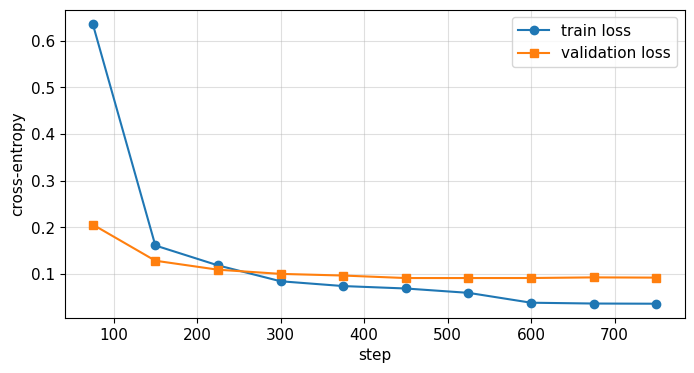

In [25]:
set_seed(SEED)
model = make_model()
history, train_seconds = train_ner(model, tokenized['train'], tokenized['validation'])
RUN_TIMES['train_main_sec'] = train_seconds
train_curve = [(h['step'], h['loss']) for h in history if 'loss' in h]
eval_curve = [(h['step'], h['eval_loss']) for h in history if 'eval_loss' in h]
assert len(train_curve) >= 2 and len(eval_curve) >= 2, 'логируйте train и eval loss по ходу обучения'
print(f'обучение: {train_seconds:.1f} c на {DEVICE_NAME}, {len(tokenized["train"])} предложений, {EPOCHS} эпох(а)')

plt.figure(figsize=(8, 4))
plt.plot(*zip(*train_curve), 'o-', label='train loss')
plt.plot(*zip(*eval_curve), 's-', label='validation loss')
plt.xlabel('step')
plt.ylabel('cross-entropy')
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

**Вопрос.** Почему выбраны такие гиперпараметры? Что видно на кривых: есть ли переобучение, нужно ли больше эпох? Сколько заняло обучение и на каком устройстве?

**Ответ:**
Я оставила learning_rate = 2e-4 из шаблона для компактной rubert-tiny2. Батч из 32 предложений позволил обрабатывать несколько примеров за шаг без слишком большой нагрузки на память. Первые 38 из 750 шагов learning rate постепенно рос, чтобы модель плавно начала обновлять веса. Для регуляризации я использовала weight_decay = 0.01, а fp16 на CPU был отключён. Три эпохи на 8 000 предложениях заняли 1 173,5 секунды, то есть около 19 минут 34 секунд, на CPU в Google Colab.

По графику train loss снизился с 0,6363 до 0,0361, а validation loss - с 0,2058 до 0,0921. Примерно после второй эпохи ошибка на валидации почти перестала снижаться, хотя на обучении ещё падала. Устойчивого роста validation loss нет, поэтому явного переобучения я не вижу. Добавлять эпохи по этому графику я бы не стала: к концу обучение ещё улучшало результат на train, а на validation заметного выигрыша уже не было.

## 4.2 Метрики (3 балла)

1. Посчитайте на validation и test отчет `seqeval` по типам (P/R/F1, support), micro и macro F1
2. Реализуйте `token_f1(gold, pred)` - micro-F1 по словам: верное срабатывание - слово, у которого предсказанный тег не `O` и совпадает с истинным; тег `O` в precision и recall не участвует; если не-`O` слов нет ни в gold, ни в pred, функция возвращает 0.0
3. Сравните токенный F1 и F1 по сущностям и объясните разницу

In [26]:
def token_f1(gold, pred):
    # gold, pred: списки списков BIO-тегов -> micro-F1 по словам без тега O
    correct = gold_count = pred_count = 0

    for gold_tags, pred_tags in zip(gold, pred, strict=True):
        for true_tag, predicted_tag in zip(gold_tags, pred_tags, strict=True):
            gold_count += true_tag != "O"
            pred_count += predicted_tag != "O"
            correct += true_tag == predicted_tag and true_tag != "O"

    total = gold_count + pred_count
    return 2 * correct / total if total else 0.0

In [27]:
g, p = [['B-PER', 'I-PER', 'O', 'B-LOC']], [['B-PER', 'O', 'O', 'B-LOC']]
assert abs(token_f1(g, p) - 0.8) < 1e-9                       # 2 верных слова из 2 предсказанных и 3 истинных
assert abs(f1_score(g, p) - 0.5) < 1e-9                       # а по сущностям верна одна из двух
assert token_f1([['O', 'O']], [['O', 'O']]) == 0.0 and token_f1(g, g) == 1.0

test_tokens = [list(words) for words in data["test"]["tokens"]]
test_gold = [
    [LABEL_NAMES[tag_id] for tag_id in tags]
    for tags in data["test"]["ner_tags"]
]

val_pred = predict_word_tags(model, val_tokens, batch_size=32)
test_pred = predict_word_tags(model, test_tokens, batch_size=32)


def report_scores(split, gold, pred):
    scores = entity_scores(gold, pred)
    scores["token_f1"] = token_f1(gold, pred)

    report = classification_report(
        gold, pred, output_dict=True, zero_division=0
    )
    scores["per_type"] = {
        kind: report[kind] for kind in ENTITY_TYPES if kind in report
    }

    lengths_by_type = collections.defaultdict(list)
    for tags in gold:
        for start, end, kind in bio_to_spans(tags):
            lengths_by_type[kind].append(end - start)

    print(f"\n{split}")
    print(", ".join(
        f"{name}={value:.4f}"
        for name, value in scores.items()
        if name != "per_type"
    ))
    print(f'{"Тип":<8} {"Precision":>10} {"Recall":>8} {"F1":>8} '
          f'{"Support":>8} {"Ср. длина":>10}')

    for kind, row in scores["per_type"].items():
        lengths = lengths_by_type[kind]
        mean_length = sum(lengths) / len(lengths) if lengths else 0.0
        print(f'{kind:<8} {row["precision"]:>10.4f} {row["recall"]:>8.4f} '
              f'{row["f1-score"]:>8.4f} {row["support"]:>8} {mean_length:>10.2f}')

    return scores


val_scores = report_scores("validation", val_gold, val_pred)
final = report_scores("test", test_gold, test_pred)


validation
f1_micro=0.7872, f1_macro=0.7318, precision=0.7654, recall=0.8102, token_f1=0.8164
Тип       Precision   Recall       F1  Support  Ср. длина
LOC          0.8623   0.8985   0.8801      739       1.08
MISC         0.5794   0.6186   0.5984      236       1.59
ORG          0.5821   0.6446   0.6118      242       1.72
PER          0.8154   0.8596   0.8369      406       1.39

test
f1_micro=0.7826, f1_macro=0.7298, precision=0.7610, recall=0.8054, token_f1=0.8091
Тип       Precision   Recall       F1  Support  Ср. длина
LOC          0.8951   0.9042   0.8996      793       1.10
MISC         0.5978   0.6506   0.6231      249       1.74
ORG          0.5839   0.6416   0.6114      293       1.68
PER          0.7424   0.8333   0.7853      294       1.39


**Вопрос.** Какой тип сущностей распознается хуже всего и почему (частота, длина спанов, разнообразие)? Чем отличаются micro и macro F1 в вашем случае? Чем отличаются токенный F1 и F1 по сущностям в ваших числах и за счет чего (какой выше и почему)? Какой из них ближе к тому, что нужно пользователю NER?

**Ответ:**
На validation хуже всего распознавались прочие сущности (MISC, F1 0,5984), а на test - организации (ORG, F1 0,6114). Оба типа реже встречаются в обучающих данных, чем названия мест. На тесте их спаны в среднем длиннее: 1,74 слова у MISC и 1,68 у ORG против 1,10 у LOC. Из-за этого сложнее угадать обе границы. Кроме того, MISC объединяет разные по смыслу сущности, и у них может быть меньше общих признаков.

На тесте micro-F1 = 0,7826, а macro-F1 = 0,7298. Названия мест составляют почти половину тестовых сущностей (793 из 1 629) и распознаются лучше всех (F1 = 0,8996), поэтому сильно влияют на micro-F1. В macro-F1 у всех четырёх типов одинаковый вес, и более низкие результаты ORG и MISC уменьшают среднее.

F1 по словам выше F1 по сущностям на обеих выборках: 0,8164 против 0,7872 на validation и 0,8091 против 0,7826 на test. Если модель правильно разметила часть названия, эти слова могут засчитаться отдельно. F1 по сущностям требует, чтобы совпали обе границы и тип. Для пользователя NER эта метрика ближе к задаче, потому что обычно ему нужно полное имя или название.

---
# 5. Анализ

## 5.1 Разбор ошибок (2 балла)

Аналог разбора ошибок детектора по IoU. Реализуйте `categorize_errors(gold_spans, pred_spans)`: каждый истинный спан получает ровно одну категорию, предсказанный спан, не пересекающийся ни с одним истинным, - категорию `spurious`. Возвращается список `(категория, истинный спан или None, предсказанный спан или None)`:

- `correct` - есть предсказанный спан с теми же границами и типом
- `boundary` - точного совпадения нет, но есть пересекающийся предсказанный спан того же типа (ошибка границы, аналог ошибки локализации)
- `type` - пересекающегося спана того же типа нет, но есть пересекающийся спан другого типа (ошибка типа, аналог ошибки класса)
- `missed` - ни один предсказанный спан не пересекается с истинным (пропуск)
- `spurious` - лишний спан (ложное срабатывание)

Посчитайте категории на validation, доли среди ошибок, покажите 5+ примеров ошибок разных категорий глазами (предложение, истинный и предсказанный спаны).

In [28]:
ERROR_CATEGORIES = ['correct', 'boundary', 'type', 'missed', 'spurious']


def categorize_errors(gold_spans, pred_spans):
    # -> [(категория, gold-спан или None, pred-спан или None), ...]
    # ваш код
    results = []
    overlapping_predictions = set()

    for gold in gold_spans:
        start, end, kind = gold
        overlaps = [
            pred for pred in pred_spans
            if max(start, pred[0]) < min(end, pred[1])
        ]
        overlapping_predictions.update(overlaps)

        same_type = next((pred for pred in overlaps if pred[2] == kind), None)

        if gold in overlaps:
            results.append(("correct", gold, gold))
        elif same_type is not None:
            results.append(("boundary", gold, same_type))
        elif overlaps:
            results.append(("type", gold, overlaps[0]))
        else:
            results.append(("missed", gold, None))

    for pred in pred_spans:
        if pred not in overlapping_predictions:
            results.append(("spurious", None, pred))

    return results

In [29]:
gold = [(0, 2, 'PER'), (4, 5, 'LOC'), (7, 9, 'ORG'), (11, 12, 'PER')]
pred = [(0, 2, 'PER'), (4, 6, 'LOC'), (7, 9, 'LOC'), (13, 14, 'ORG')]
res = categorize_errors(gold, pred)
assert collections.Counter(c for c, _, _ in res) == {'correct': 1, 'boundary': 1, 'type': 1, 'missed': 1, 'spurious': 1}
assert ('type', (7, 9, 'ORG'), (7, 9, 'LOC')) in res and ('spurious', None, (13, 14, 'ORG')) in res
assert ('boundary', (4, 5, 'LOC'), (4, 6, 'LOC')) in res and ('missed', (11, 12, 'PER'), None) in res
assert categorize_errors([], []) == [] and categorize_errors([], [(0, 1, 'PER')]) == [('spurious', None, (0, 1, 'PER'))]
assert [c for c, _, _ in categorize_errors([(0, 3, 'LOC')], [(1, 2, 'PER'), (2, 3, 'LOC')])] == ['boundary']
assert [c for c, _, _ in categorize_errors([(0, 2, 'LOC'), (2, 4, 'LOC')], [(0, 4, 'LOC')])] == ['boundary', 'boundary']
assert sorted(c for c, _, _ in categorize_errors([(0, 2, 'PER')], [(2, 3, 'PER')])) == ['missed', 'spurious']   # end не включается: спаны только соприкасаются

# ваш код: {категория: число} на validation, затем доли и 5+ примеров

counts = collections.Counter()
examples = collections.defaultdict(list)

for index, (words, gold_tags, pred_tags) in enumerate(
    zip(val_tokens, val_gold, val_pred, strict=True)
):
    gold_spans = bio_to_spans(gold_tags)
    pred_spans = bio_to_spans(pred_tags)
    for category, gold_span, pred_span in categorize_errors(gold_spans, pred_spans):
        counts[category] += 1
        if category != "correct" and len(examples[category]) < 3:
            examples[category].append((index, words, gold_span, pred_span))

errors = {category: counts[category] for category in ERROR_CATEGORIES}
n_errors = sum(errors.values()) - errors["correct"]

print(f"Точные совпадения: {errors['correct']}")
print(f"Ошибки: {n_errors}")
for category in ERROR_CATEGORIES[1:]:
    share = errors[category] / n_errors if n_errors else 0.0
    print(f"{category}: {errors[category]} ({share:.1%} ошибок)")


def format_span(words, span):
    if span is None:
        return "—"
    start, end, kind = span
    phrase = " ".join(words[start:end])
    return f"«{phrase}» ({kind}, [{start}, {end}))"


for category in ERROR_CATEGORIES[1:]:
    for index, words, gold_span, pred_span in examples[category]:
        print(f"\n{category}, validation[{index}]")
        print("Предложение:", " ".join(words))
        print("Разметка:", format_span(words, gold_span))
        print("Предсказание:", format_span(words, pred_span))

Точные совпадения: 1315
Ошибки: 392
boundary: 106 (27.0% ошибок)
type: 157 (40.1% ошибок)
missed: 45 (11.5% ошибок)
spurious: 84 (21.4% ошибок)

boundary, validation[1]
Предложение: Брокхауз стал профессором в университете Мак-Мастера в Канаде , где и оставался до пенсии в 1984 г .
Разметка: «университете Мак-Мастера» (LOC, [4, 6))
Предсказание: «Мак-Мастера» (LOC, [5, 6))

boundary, validation[13]
Предложение: 23 декабря 2007 года подписал двухлетний контракт с новосибирской « Сибирью » , осуществив мечту играть за родной город .
Разметка: «Сибирью »» (ORG, [10, 12))
Предсказание: «»» (ORG, [11, 12))

boundary, validation[20]
Предложение: Хотя ранее сообщалось , что к футболисту проявлял пристальный интерес московский ЦСКА .
Разметка: «московский ЦСКА» (ORG, [10, 12))
Предсказание: «ЦСКА» (ORG, [11, 12))

type, validation[10]
Предложение: Шошоны из районов Титон и Йеллоустон были переселены в резервацию Уинд-Ривер , после того как она была создана в 1868 году .
Разметка: «Йеллоустон» 

**Вопрос.** Какая категория ошибок самая частая? Что общего у примеров в каждой категории? Какие ошибки - на самом деле ошибки разметки, а не модели? Что бы вы сделали, чтобы уменьшить самую частую категорию?

**Ответ:**
На validation чаще всего модель ошибалась в типе сущности - 157 из 392 ошибок (40,1%). Например, «Йеллоустон» она отметила как человека (PER) вместо места (LOC), а «Хуареса» во фразе «правительством Хуареса» - как место вместо человека.

При ошибках границ модель выделяла только часть названия, например «ЦСКА» вместо «московский ЦСКА». Среди пропущенных сущностей были «Давным-давно» и «Синяя птица», размеченные как MISC. А слово «апостолами» модель ошибочно выделила как PER, хотя в этом предложении оно обозначает роль, а не имя.

В примере с хоккейной командой «Сибирь» в размеченный спан попала закрывающая кавычка. Это похоже на ошибку разметки, хотя предсказание одной кавычки тоже ошибочно. Чтобы уменьшить число ошибок типа, я бы добавила в train проверенные примеры, в которых похожие названия относятся к разным типам. Например, фразы вроде «в районе Йеллоустона» и «правительство Хуареса» помогают научиться различать место и человека по контексту. Затем я бы проверила, стало ли ошибок типа меньше на той же validation.

## 5.2 Абляция (1 балл)

Один дополнительный эксперимент на выбор, все остальное как в 4.1:

- `'freeze'` - замороженный энкодер (учится только голова) vs полное дообучение. Сравните F1, время и число обучаемых параметров
- `'all_subwords'` - метка на все сабворды (`data.map(tokenize_and_align, batched=True, remove_columns=data['train'].column_names, fn_kwargs=dict(label_all_subwords=True))`) vs только на первый. Оценка по-прежнему по словам через `predict_word_tags`

Результат положите в `ablation` - словарь с настройкой и метриками обоих вариантов.

In [30]:
ABLATION = 'freeze'   # 'freeze' или 'all_subwords'
# ваш код

set_seed(SEED)
frozen_model = make_model()
_, frozen_seconds = train_ner(
    frozen_model, tokenized["train"], tokenized["validation"],
    freeze_encoder=True, out_dir="runs/freeze",
)
frozen_pred = predict_word_tags(frozen_model, val_tokens, batch_size=32)

ablation = {
    "setting": ABLATION,
    "full": {
        **entity_scores(val_gold, val_pred),
        "seconds": RUN_TIMES["train_main_sec"],
        "trainable_params": sum(p.numel() for p in model.parameters() if p.requires_grad),
    },
    "frozen": {
        **entity_scores(val_gold, frozen_pred),
        "seconds": frozen_seconds,
        "trainable_params": sum(p.numel() for p in frozen_model.parameters() if p.requires_grad),
    },
}
for name in ("full", "frozen"):
    row = ablation[name]
    print(f"{name}: micro-F1={row['f1_micro']:.4f}, "
          f"время={row['seconds']:.1f} с, параметров={row['trainable_params']:,}")
print(f"Разница micro-F1 (frozen − full): "
      f"{ablation['frozen']['f1_micro'] - ablation['full']['f1_micro']:+.4f}")
print(f"Отношение времени full / frozen: "
      f"{ablation['full']['seconds'] / ablation['frozen']['seconds']:.2f}×")
del frozen_model

Loading weights:   0%|          | 0/53 [00:00<?, ?it/s]

{'loss': '1.64', 'grad_norm': '3.078', 'learning_rate': '0.0001899', 'epoch': '0.3'}
{'eval_loss': '1.009', 'eval_runtime': '8.176', 'eval_samples_per_second': '122.3', 'eval_steps_per_second': '3.914', 'epoch': '0.3'}
{'loss': '0.684', 'grad_norm': '0.7015', 'learning_rate': '0.0001688', 'epoch': '0.6'}
{'eval_loss': '0.4969', 'eval_runtime': '7.639', 'eval_samples_per_second': '130.9', 'eval_steps_per_second': '4.189', 'epoch': '0.6'}
{'loss': '0.4317', 'grad_norm': '0.4389', 'learning_rate': '0.0001478', 'epoch': '0.9'}
{'eval_loss': '0.4036', 'eval_runtime': '9.154', 'eval_samples_per_second': '109.2', 'eval_steps_per_second': '3.496', 'epoch': '0.9'}
{'loss': '0.3707', 'grad_norm': '0.3606', 'learning_rate': '0.0001267', 'epoch': '1.2'}
{'eval_loss': '0.3626', 'eval_runtime': '8.777', 'eval_samples_per_second': '113.9', 'eval_steps_per_second': '3.646', 'epoch': '1.2'}
{'loss': '0.3439', 'grad_norm': '0.3384', 'learning_rate': '0.0001056', 'epoch': '1.5'}
{'eval_loss': '0.3371', '

**Вопрос.** Насколько изменилась метрика и время? Чем вы объясняете результат? Что бы вы проверили следующим шагом, чтобы вывод был надежнее?

**Ответ:**
Когда я заморозила энкодер, micro-F1 на validation упал с 0,7872 до 0,4353, то есть на 0,3519. Зато обучение на CPU заняло 469,9 секунды вместо 1 173,5 - примерно в 2,5 раза быстрее. Число обучаемых параметров сократилось с 29 098 929 до 2 817, потому что обновлялась только голова.

Ускорение объясняется тем, что для энкодера больше не нужно считать градиенты. При этом голова получала готовые представления токенов, а при полном дообучении энкодер тоже подстраивался под задачу NER. В моём прогоне это дало заметно более высокий F1.

Чтобы проверить, насколько устойчив результат, я бы повторила оба варианта с несколькими значениями seed на тех же выборках и сравнила средний F1 и разброс между запусками.

## 5.3 Выводы (1 балл)

5-8 предложений с числами: что сработало, что нет, главные ограничения (данные, разметка, модель, бюджет), что бы вы сделали дальше.

**Ответ:**
После дообучения rubert-tiny2 micro-F1 на validation вырос с 0,4024 у словарного бейзлайна до 0,7872, а на test модель получила 0,7826. Лучше всего на тесте она распознавала названия мест (LOC, F1 0,8996), хуже всего - организации (ORG, F1 0,6114). На validation самой частой ошибкой оказалась путаница типов - 157 случаев из 392. Заморозка энкодера ускорила обучение в 2,5 раза, но micro-F1 на validation упал до 0,4353. Перевод текста в верхний регистр тоже сильно снизил качество - до 0,0321. Из-за ограниченного времени на CPU я обучалась на подвыборке из 8 000 предложений с автоматически полученной разметкой и провела эксперимент с одним seed. Дальше я бы вручную проверила спорные примеры ORG и MISC, добавила похожие случаи с аккуратной разметкой и повторила обучение с несколькими seed.

### Сохранение результатов

Ячейка сохраняет `artifacts/metrics.json`. Выполняется и в `FAST_MODE` для проверки формата, при финальном прогоне перезаписывается с `fast_mode: false`. Сдайте файл вместе с ноутбуком.

In [31]:
def json_ready(value):
    if isinstance(value, torch.Tensor):
        return json_ready(value.detach().cpu().tolist())
    if isinstance(value, np.ndarray):
        return json_ready(value.tolist())
    if isinstance(value, dict):
        return {str(k): json_ready(v) for k, v in value.items()}
    if isinstance(value, (tuple, list)):
        return [json_ready(v) for v in value]
    if isinstance(value, (float, np.floating)):
        return float(value) if math.isfinite(value) else None
    if isinstance(value, np.integer):
        return int(value)
    if isinstance(value, Path):
        return value.as_posix()
    return value


metrics = dict(
    track='nlp', model=MODEL_ID, revision=REVISION,
    dataset=f'{DATASET_ID}/{DATASET_CONFIG}' if DATASET_CONFIG else str(DATASET_ID), classes=ENTITY_TYPES,
    n_train=len(data['train']), n_val=len(data['validation']), n_test=len(data['test']),
    params_total=sum(p.numel() for p in model.parameters()),
    baseline=baseline, final=final, ablation=ablation, errors=errors,
    device=DEVICE_NAME, train_time_sec=RUN_TIMES.get('train_main_sec'), fast_mode=FAST_MODE)
for key in ['f1_micro', 'f1_macro', 'precision', 'recall', 'token_f1', 'per_type']:
    assert key in final, f'в final нет {key}'
(ARTIFACTS / 'metrics.json').write_text(json.dumps(json_ready(metrics), ensure_ascii=False, indent=2), encoding='utf-8')
print(json.dumps(json_ready({k: v for k, v in metrics.items() if k not in ('final', 'baseline')}), ensure_ascii=False)[:600])
print('final F1 micro', round(final['f1_micro'], 4))

{"track": "nlp", "model": "cointegrated/rubert-tiny2", "revision": "e8ed3b0c8bbf4fb6984c3de043bf7d2f4e5969ae", "dataset": "Babelscape/wikineural", "classes": ["LOC", "MISC", "ORG", "PER"], "n_train": 8000, "n_val": 1000, "n_test": 1000, "params_total": 29098929, "ablation": {"setting": "freeze", "full": {"f1_micro": 0.7871894642322658, "f1_macro": 0.7317772081243579, "precision": 0.7654249126891735, "recall": 0.8102279728897104, "seconds": 1173.5066844779997, "trainable_params": 29098929}, "frozen": {"f1_micro": 0.43532145623547636, "f1_macro": 0.21919031464828678, "precision": 0.5860271115745
final F1 micro 0.7826


---
# 6\*. Бонусные задачи

Включаются через `BONUS_TASKS`, за бонусы суммарно - до 4 баллов из 5.5 предложенных.

## 6.1 Доразметка (1.5 балла)

Разметьте сами 50+ новых предложений (Label Studio, doccano или вручную в JSON): например, тексты из другого источника или трудные случаи из 5.1. Опишите инструкцию разметки, приведите разметку к контракту из 2.1, добавьте в train (или сделайте отдельный test) и покажите, как изменилась метрика. Файл с разметкой приложите к сдаче.

In [32]:
if '6.1' in BONUS_TASKS:
    # ваш код
    pass

**Вопрос.** Сколько и каких примеров вы разметили, сколько времени заняла разметка, как изменилась метрика и на каком сплите? Где вы сами сомневались в разметке?

**Ответ:**

## 6.2 Другая модель (1 балл)

Сравните с другим энкодером (многоязычный vs одноязычный, base vs маленький) при том же протоколе - или zero-shot NER открытой LLM с Hugging Face против дообученного энкодера. Сравните F1, время обучения и инференса, размер.

In [33]:
if '6.2' in BONUS_TASKS:
    # ваш код
    alt_id = "cointegrated/rubert-tiny"
    alt_revision = "5441c5ea8026d4f6d7505ec004845409f1259fb1"
    alt_tok = AutoTokenizer.from_pretrained(alt_id, revision=alt_revision)
    assert alt_tok.is_fast
    alt_tokenized = data.map(
        tokenize_and_align, batched=True,
        remove_columns=data["train"].column_names,
        fn_kwargs={"tok": alt_tok},
    )

    set_seed(SEED)
    alt_model = make_model(alt_id, alt_revision)
    _, alt_seconds = train_ner(
        alt_model, alt_tokenized["train"], alt_tokenized["validation"],
        tok=alt_tok, out_dir="runs/alt",
    )

    model_comparison = {}
    for name, candidate, tok, train_time in [
        (MODEL_ID, model, tokenizer, RUN_TIMES["train_main_sec"]),
        (alt_id, alt_model, alt_tok, alt_seconds),
    ]:
        predict_word_tags(candidate, val_tokens[:32], tok=tok, batch_size=32)
        if device.type == "cuda":
            torch.cuda.synchronize()
        start = time.perf_counter()
        predictions = predict_word_tags(candidate, val_tokens, tok=tok, batch_size=32)
        if device.type == "cuda":
            torch.cuda.synchronize()
        infer_seconds = time.perf_counter() - start
        parameters = tuple(candidate.parameters())
        scores = entity_scores(val_gold, predictions)
        scores.update(
            train_seconds=train_time,
            inference_ms_per_sentence=1000 * infer_seconds / len(val_tokens),
            params=sum(p.numel() for p in parameters),
            weight_mib=sum(p.numel() * p.element_size() for p in parameters) / 2**20,
        )
        model_comparison[name] = scores
        print(f"{name}: F1={scores['f1_micro']:.4f}, обучение {train_time:.1f} с, "
              f"инференс {scores['inference_ms_per_sentence']:.2f} мс/предложение, "
              f"{scores['params']:,} параметров, веса {scores['weight_mib']:.1f} МиБ")
    print(f"Обе модели оценены на одном validation, устройство: {DEVICE_NAME}.")
    del alt_model, candidate, parameters

config.json:   0%|          | 0.00/632 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/341 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/241k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/468k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

Map:   0%|          | 0/8000 [00:00<?, ? examples/s]

... (2 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B / 47.7MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/53 [00:00<?, ?it/s]

{'loss': '0.6686', 'grad_norm': '0.7785', 'learning_rate': '0.0001899', 'epoch': '0.3'}
{'eval_loss': '0.2096', 'eval_runtime': '18.06', 'eval_samples_per_second': '55.37', 'eval_steps_per_second': '1.772', 'epoch': '0.3'}
{'loss': '0.1672', 'grad_norm': '0.633', 'learning_rate': '0.0001688', 'epoch': '0.6'}
{'eval_loss': '0.1383', 'eval_runtime': '12.22', 'eval_samples_per_second': '81.84', 'eval_steps_per_second': '2.619', 'epoch': '0.6'}
{'loss': '0.1306', 'grad_norm': '0.6555', 'learning_rate': '0.0001478', 'epoch': '0.9'}
{'eval_loss': '0.1139', 'eval_runtime': '11.42', 'eval_samples_per_second': '87.59', 'eval_steps_per_second': '2.803', 'epoch': '0.9'}
{'loss': '0.0954', 'grad_norm': '0.6831', 'learning_rate': '0.0001267', 'epoch': '1.2'}
{'eval_loss': '0.1066', 'eval_runtime': '11.65', 'eval_samples_per_second': '85.85', 'eval_steps_per_second': '2.747', 'epoch': '1.2'}
{'loss': '0.08456', 'grad_norm': '1.035', 'learning_rate': '0.0001056', 'epoch': '1.5'}
{'eval_loss': '0.1018

**Вопрос.** Что лучше и какой ценой (время, память)? Как вы обеспечили честность сравнения?

**Ответ:**
моём прогоне rubert-tiny2 показала себя лучше. На validation её micro-F1 составил 0,7872 против 0,7691 у rubert-tiny. На CPU она также быстрее обучилась (1 173,5 с против 1 353,2 с) и быстрее обрабатывала текст (9,42 мс на предложение против 12,64 мс). При этом её веса занимают примерно в 2,5 раза больше памяти - 111,0 МиБ против 44,6 МиБ.

Для сравнения я обучила обе модели на одной и той же выборке из 8 000 предложений, по три эпохи с одинаковыми настройками. Качество и скорость проверила на одних и тех же 1 000 предложениях validation, на одном CPU и с одинаковым размером батча. У каждой модели был свой токенизатор.

## 6.3 Устойчивость к сдвигу (1 балл)

Испортите validation и посмотрите на F1: опечатки, весь текст в нижнем или верхнем регистре, транслит, или другой домен (новости, соцсети, другой датасет с теми же типами). Метки при порче не меняются.

In [34]:
if '6.3' in BONUS_TASKS:
    # ваш код
    shift_scores = {"исходный": entity_scores(val_gold, val_pred)}
    reference_f1 = shift_scores["исходный"]["f1_micro"]
    print(f"Исходный текст: micro-F1={reference_f1:.4f}")

    for name, transform in [("нижний регистр", str.lower), ("верхний регистр", str.upper)]:
        shifted_tokens = [[transform(word) for word in words] for words in val_tokens]
        shifted_pred = predict_word_tags(model, shifted_tokens, batch_size=32)
        scores = entity_scores(val_gold, shifted_pred)
        shift_scores[name] = scores
        print(f"{name}: micro-F1={scores['f1_micro']:.4f}, "
              f"разница {scores['f1_micro'] - reference_f1:+.4f}")

Исходный текст: micro-F1=0.7872
нижний регистр: micro-F1=0.1554, разница -0.6317
верхний регистр: micro-F1=0.0321, разница -0.7551


**Вопрос.** Какая порча сильнее всего роняет F1 и почему (вспомните, как токенизатор режет слова и какие признаки сущности есть в тексте)?

**Ответ:**
Сильнее всего качество упало, когда я перевела весь текст в верхний регистр. На исходном validation micro-F1 был 0,7872, в нижнем регистре - 0,1554, а в верхнем - 0,0321. Разметка во всех трёх случаях была одинаковой.

Регистр помогает модели замечать имена и названия. В нижнем регистре пропадает заглавная буква в начале имени, а в верхнем заглавными становятся и обычные слова. Кроме того, токенизатор учитывает регистр, поэтому варианты вроде Москва и МОСКВА могут разбиваться на разные сабворды. Это может объяснять, почему верхний регистр оказался самым трудным.

## 6.4 Экспорт и скорость (1 балл)

Экспортируйте модель в ONNX (или примените `torch.compile` / квантизацию), замерьте задержку до и после на одном и том же батче и устройстве (с прогревом, среднее по 10+ запускам) и проверьте, что F1 не упал (или упал незначительно).

Для ONNX: `%pip install -q onnx onnxruntime onnxscript`.

In [35]:
if '6.4' in BONUS_TASKS:
    # ваш код
    cpu = torch.device("cpu")
    fp32_model = copy.deepcopy(model).to(cpu).float().eval()
    int8_model = torch.ao.quantization.quantize_dynamic(
        fp32_model, {torch.nn.Linear}, dtype=torch.qint8,
    ).eval()

    speed_batch = tokenizer(
        val_tokens[:32], is_split_into_words=True, truncation=True,
        max_length=MAX_LENGTH, padding=True, return_tensors="pt",
    )
    quantization_scores = {}
    for name, candidate in [("FP32", fp32_model), ("INT8", int8_model)]:
        with torch.inference_mode():
            for _ in range(3):
                candidate(**speed_batch)
            start = time.perf_counter()
            for _ in range(20):
                candidate(**speed_batch)
            latency_ms = (time.perf_counter() - start) * 1000 / 20

        predictions = predict_word_tags(candidate, val_tokens, batch_size=32, dev=cpu)
        f1 = entity_scores(val_gold, predictions)["f1_micro"]
        quantization_scores[name] = {"batch_ms": latency_ms, "f1_micro": f1}
        print(f"{name}: {latency_ms:.2f} мс на батч, micro-F1={f1:.4f}")

    before, after = quantization_scores["FP32"], quantization_scores["INT8"]
    print(f"CPU, батч {tuple(speed_batch['input_ids'].shape)}. "
          f"Ускорение {before['batch_ms'] / after['batch_ms']:.2f}×, "
          f"разница F1 {after['f1_micro'] - before['f1_micro']:+.4f}")
    del fp32_model, int8_model, candidate

/tmp/ipykernel_5760/118302575.py:5: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  int8_model = torch.ao.quantization.quantize_dynamic(
/usr/local/lib/python3.13/dist-packages/torch/ao/nn/quantized/modules/utils.py:72: UserWarning: torch.quantize_per_tensor, torch.quantize_per_channel and other quantized tensor creation functions that produce tensors with dtype torch.quin

FP32: 257.06 мс на батч, micro-F1=0.7872
INT8: 194.57 мс на батч, micro-F1=0.7903
CPU, батч (32, 63). Ускорение 1.32×, разница F1 +0.0031


**Вопрос.** Какое ускорение и на каком устройстве? Изменилась ли метрика? Почему выигрыш зависит от модели (вспомните, где у вашей модели основная часть параметров и вычислений)?

**Ответ:**
На CPU в Colab после квантизации задержка снизилась с 257,06 мс до 194,57 мс на одном и том же батче из 32 предложений. Это ускорение в 1,32 раза. Время я усреднила по 20 запускам после прогрева. Micro-F1 на validation почти не изменился: 0,7872 у FP32 и 0,7903 у INT8.

У rubert-tiny2 около 92% параметров находятся в эмбеддингах, которые в этом эксперименте остались в FP32. В INT8 я перевела линейные слои энкодера и головы. Они выполняют много матричных умножений, поэтому выигрыш в скорости всё равно есть. Его размер зависит от того, сколько времени у конкретной модели занимают операции, которые удалось ускорить.

## 6.5 Порог уверенности спана (1 балл)

Уверенность спана - средняя (или минимальная) по словам спана вероятность предсказанного тега (`predict_word_tags(..., return_probs=True)`). Отбрасывая спаны ниже порога, постройте кривую precision-recall по сущностям на validation и найдите порог с лучшим F1.

средняя: лучший порог 0.7621, F1=0.8056, при пороге 0 F1=0.7872, прирост +0.0184
минимальная: лучший порог 0.6192, F1=0.8035, при пороге 0 F1=0.7872, прирост +0.0163


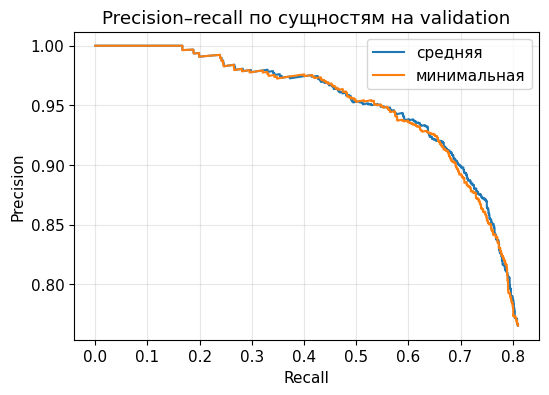

In [36]:
if '6.5' in BONUS_TASKS:
    # ваш код
    from itertools import groupby

    confidence_tags, word_probs = predict_word_tags(
        model, val_tokens, batch_size=32, return_probs=True,
    )
    gold_spans_by_sentence = [set(bio_to_spans(tags)) for tags in val_gold]
    n_gold = sum(len(spans) for spans in gold_spans_by_sentence)
    candidates = {"средняя": [], "минимальная": []}

    for tags, probs, true_spans in zip(
        confidence_tags, word_probs, gold_spans_by_sentence, strict=True
    ):
        for span in bio_to_spans(tags):
            start, end, _ = span
            span_probs = probs[start:end]
            correct = int(span in true_spans)
            candidates["средняя"].append((sum(span_probs) / len(span_probs), correct))
            candidates["минимальная"].append((min(span_probs), correct))

    threshold_results = {}
    plt.figure(figsize=(6, 4))
    for name, items in candidates.items():
        ordered = sorted(items, key=lambda item: item[0], reverse=True)
        kept = matched = 0
        curve = []
        for threshold, group in groupby(ordered, key=lambda item: item[0]):
            for _, correct in group:
                kept += 1
                matched += correct
            precision = matched / kept
            recall = matched / n_gold if n_gold else 0.0
            f1 = 2 * matched / (kept + n_gold)
            curve.append((threshold, precision, recall, f1))

        baseline_f1 = curve[-1][3] if curve else 0.0
        curve.append((0.0, matched / kept if kept else 0.0,
                      matched / n_gold if n_gold else 0.0, baseline_f1))
        best = max(curve, key=lambda row: (row[3], -row[0]))
        threshold_results[name] = {
            "threshold": best[0], "precision": best[1], "recall": best[2],
            "f1": best[3], "f1_at_zero": baseline_f1,
        }
        plt.plot([0.0] + [row[2] for row in curve],
                 [1.0] + [row[1] for row in curve], label=name)
        print(f"{name}: лучший порог {best[0]:.4f}, F1={best[3]:.4f}, "
              f"при пороге 0 F1={baseline_f1:.4f}, прирост {best[3] - baseline_f1:+.4f}")

    plt.xlabel("Recall")
    plt.ylabel("Precision")
    plt.title("Precision–recall по сущностям на validation")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

**Вопрос.** Какой порог дает лучший F1 и сколько он добавляет к порогу 0? Чем отличаются средняя и минимальная уверенность? Почему порог по уверенности не может поднять recall?

**Ответ:**
На validation лучший результат дала средняя уверенность с порогом 0,7621. Micro-F1 вырос с 0,7872 при пороге 0 до 0,8056, то есть на 0,0184. Для минимальной уверенности лучший порог был 0,6192, а F1 - 0,8035.

Средняя уверенность учитывает оценки всех слов спана, поэтому одно слово с низкой оценкой могут компенсировать остальные. Минимальная берёт оценку самого неуверенно размеченного слова. Повышение порога убирает часть уже найденных спанов. Если убрать ложные срабатывания, precision может вырасти. Recall может остаться прежним или упасть, потому что новые правильные спаны от фильтрации не появляются.